# Lending Club Credit Risk: from PD to Capital
A full retail credit-risk workflow on Lending Club consumer loans:
**PD model → EAD → LGD → Expected Loss → credit VaR / Expected Shortfall → Basel IRB capital → stress tests → model validation → IFRS 9 staging and ECL.**

**Data:** [All Lending Club loan data](https://www.kaggle.com/datasets/wordsforthewise/lending-club) (Kaggle, CC0): 36-month loans issued 2012-2014 that have finished, so every outcome is known.

**Discipline:** models are fitted on **dev** (60%), choices are made on **test** (20%), and the **holdout** (20%) is scored once, in Part 2.

## Settings

In [1]:
RHO = 0.08                      # asset correlation for the main VaR run
RHO_GRID = [0.03, 0.08, 0.15]   # sensitivity
QUANTILES = (0.99, 0.999)       # VaR / ES confidence levels
LGD_KEEP_RULE = 0.005           # use the LGD regression only if it cuts test RMSE by >= 0.5%
SICR_MULT = 2.0                 # IFRS 9 Stage 2 proxy: PD >= SICR_MULT x dev default rate
STRESS = {                      # name: (PD multiplier, LGD add-on)
    "Base": (1.0, 0.00),
    "PD x1.5": (1.5, 0.00),
    "PD x2": (2.0, 0.00),
    "LGD +10 pts": (1.0, 0.10),
    "PD x2, LGD +10 pts": (2.0, 0.10),
}

# Part 1: build the models (dev and test)
## Step 1. Data

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_prep import load_loans
from risk_helpers import *
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

loans, cleaning_log = load_loans()
data = add_loss_columns(loans)
dev, test, hold = [data[data["split"] == s].copy() for s in ["dev", "test", "holdout"]]
print(cleaning_log.to_string(index=False))
print(f"\ndev {len(dev):,} | test {len(test):,} | holdout {len(hold):,} | default rate {data['default'].mean():.1%}")

                                                 step  loans
            36-month loans issued 2012-2014, finished 306462
                        removed: a key field is blank    174
removed: dti outside 0-60 or rare home ownership type     76
                                           loans used 306212

dev 183,909 | test 61,345 | holdout 60,958 | default rate 13.2%


## Step 2. PD model (logistic regression)
Probability of default over the loan's life, from application data only (no Lending Club grade or interest rate,
which are Lending Club's own risk assessment).

In [3]:
pd_model = fit_pd_model(dev)
for d in (dev, test, hold):
    d["pd"] = pd_model.predict(d)
print(f"dev AUC {validation_summary(dev['default'], dev['pd'])['AUC']:.3f} | "
      f"test AUC {validation_summary(test['default'], test['pd'])['AUC']:.3f}")

dev AUC 0.654 | test AUC 0.654


In [4]:
b = pd_model.params
plain = pd.Series({
    "+10 FICO points": np.exp(10 * b["fico"]),
    "+5 dti points": np.exp(5 * b["dti"]),
    "income doubles": np.exp(np.log(2) * b["log_income"]),
    "loan amount doubles": np.exp(np.log(2) * b["log_amount"]),
    "+1 credit inquiry (6 months)": np.exp(b["inq_last_6mths"]),
    "+5 years of credit history": np.exp(5 * b["history_years"]),
    "job tenure left blank": np.exp(b["emp_missing"]),
}, name="odds of default multiplied by").round(3)
odds_ratios(pd_model).to_csv(RES / "pd_odds_ratios.csv")
plain

+10 FICO points                0.8890
+5 dti points                  1.0950
income doubles                 0.7040
loan amount doubles            1.2090
+1 credit inquiry (6 months)   1.1730
+5 years of credit history     0.9630
job tenure left blank          1.3860
Name: odds of default multiplied by, dtype: float64

## Step 3. Exposure at Default (EAD)
EAD = funded amount − principal repaid, for loans that defaulted.

In [5]:
dev_def = dev[dev["default"] == 1]
print(f"Defaulted dev loans: {len(dev_def):,}  |  mean EAD = {dev_def['ead_pct'].mean():.1%} of funded amount")
ead_grade = dev_def.groupby("grade").agg(loans=("id", "size"), ead_pct=("ead_pct", "mean"), ead_mean=("ead", "mean"))
ead_grade.to_csv(RES / "ead_by_grade.csv")
ead_grade

Defaulted dev loans: 24,290  |  mean EAD = 57.4% of funded amount


,loans,ead_pct,ead_mean
grade,,,
A,2080,0.5147,"6,810.8116"
B,7131,0.5443,"6,623.8003"
C,7830,0.5729,"6,816.5088"
D,5082,0.6083,"7,290.5614"
E,1670,0.6488,"7,645.5087"
F,449,0.6804,"7,079.5857"
G,48,0.6967,"9,820.8331"


In [6]:
ead_fico = dev_def.groupby("fico_band", observed=True).agg(loans=("id", "size"), ead_pct=("ead_pct", "mean"))
ead_fico.to_csv(RES / "ead_by_fico.csv")
ead_fico

,loans,ead_pct
fico_band,,
<680,10929,0.5823
680-699,7457,0.5719
700-719,3612,0.5610
720-749,1692,0.5605
750+,600,0.5804


## Step 4. Loss Given Default (LGD)
LGD = 1 − (recoveries − collection fee) / EAD, clipped to [0, 1]. Two models fitted on defaulted dev loans,
compared on defaulted test loans.

In [7]:
print(dev_def["lgd"].describe().round(3))
print("\nShare of defaults with nothing recovered (LGD = 100%):", f"{(dev_def['lgd'] == 1).mean():.1%}")

count   24,290.0000
mean         0.8880
std          0.1220
min          0.0000
25%          0.8560
50%          0.8850
75%          0.9980
max          1.0000
Name: lgd, dtype: float64

Share of defaults with nothing recovered (LGD = 100%): 16.2%


In [8]:
seg, reg = fit_lgd_models(dev_def)
test_def = test[test["default"] == 1]
lgd_test = error_table(test_def["lgd"], {
    "overall mean": np.full(len(test_def), dev_def["lgd"].mean()),
    "segment (grade)": predict_lgd("segment", seg, reg, test_def),
    "regression": predict_lgd("regression", seg, reg, test_def)})
gain = 1 - lgd_test.loc[2, "RMSE"] / lgd_test.loc[1, "RMSE"]
LGD_CHOICE = "regression" if gain >= LGD_KEEP_RULE else "segment"
lgd_test.to_csv(RES / "lgd_model_test.csv", index=False)
print("Mean LGD by grade (dev):", seg.round(3).to_dict())
print(f"Regression R-squared (dev): {reg.rsquared:.4f}\n")
print(lgd_test.to_string(index=False))
print(f"\nRegression cuts test RMSE by {gain:.2%} -> chosen LGD model: {LGD_CHOICE}")

Mean LGD by grade (dev): {'A': 0.893, 'B': 0.891, 'C': 0.889, 'D': 0.885, 'E': 0.875, 'F': 0.877, 'G': 0.874}
Regression R-squared (dev): 0.0087

          model    MAE   RMSE  bias (pred - actual)
   overall mean 0.0736 0.1135               -0.0042
segment (grade) 0.0734 0.1135               -0.0043
     regression 0.0731 0.1131               -0.0044

Regression cuts test RMSE by 0.35% -> chosen LGD model: segment


## Step 5. When defaults happen: lifetime PD term structure
A loan is treated as defaulted when it is 90 days past due (3 months after its last payment).
F(t) = share of lifetime defaults that have happened by month t (from dev). Cumulative PD by month t = lifetime PD × F(t).

Share of lifetime defaults by month 12: 22.7% | by month 24: 66.6%


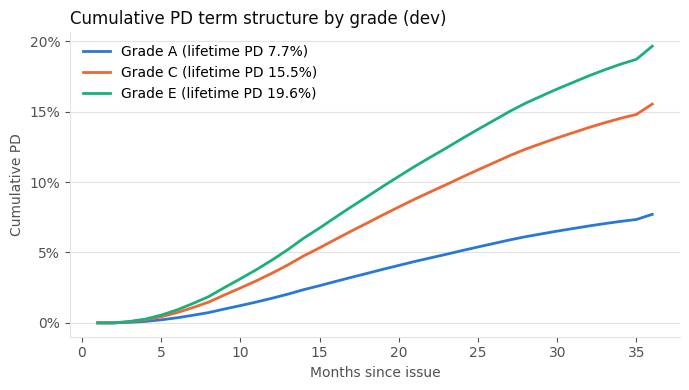

In [9]:
F = timing_curve(dev_def)
F.to_frame("share_of_defaults_by_month").to_csv(RES / "default_timing_curve.csv")
print(f"Share of lifetime defaults by month 12: {F[12]:.1%} | by month 24: {F[24]:.1%}")
fig, ax = plt.subplots(figsize=(7, 4))
for g, c in {"A": BLUE, "C": ORANGE, "E": AQUA}.items():
    pd_g = dev.loc[dev["grade"] == g, "pd"].mean()
    ax.plot(F.index, pd_g * F.values, color=c, lw=2, label=f"Grade {g} (lifetime PD {pd_g:.1%})")
style(ax, "Cumulative PD term structure by grade (dev)", "Months since issue", "Cumulative PD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "pd_term_structure.png", dpi=150); plt.show()

## Step 6. Vintage analysis (dev)

In [10]:
dev["vintage"] = dev["issue_d"].dt.to_period("Q").astype(str)
vint = dev.groupby("vintage").agg(loans=("id", "size"), predicted_pd=("pd", "mean"),
                                  default_rate=("default", "mean"), funded=("funded_amnt", "sum"),
                                  loss=("actual_loss", "sum"))
vint["loss_rate"] = vint["loss"] / vint["funded"]
vint.to_csv(RES / "vintage_dev.csv")
vint[["loans", "predicted_pd", "default_rate", "loss_rate"]]

,loans,predicted_pd,default_rate,loss_rate
vintage,,,,
2012Q1,3926,0.1154,0.1276,0.0677
2012Q2,5097,0.1229,0.1344,0.0724
2012Q3,7999,0.1309,0.1429,0.0782
2012Q4,9084,0.1315,0.1286,0.0644
2013Q1,10716,0.1320,0.1256,0.0627
2013Q2,13943,0.1291,0.1272,0.0632
2013Q3,16364,0.1287,0.1207,0.0580
2013Q4,19107,0.1274,0.1214,0.0589
2014Q1,20347,0.1345,0.1299,0.0626


## Step 7. IFRS 9 Stage 2 rule, checked on test

In [11]:
sicr_cut = SICR_MULT * dev["default"].mean()
flag = test["pd"] >= sicr_cut
print(f"Stage 2 proxy: PD >= {sicr_cut:.1%}  |  flags {flag.mean():.1%} of test loans")
print(f"Test default rate: flagged {test.loc[flag, 'default'].mean():.1%} vs not flagged {test.loc[~flag, 'default'].mean():.1%}")

Stage 2 proxy: PD >= 26.4%  |  flags 3.6% of test loans
Test default rate: flagged 28.8% vs not flagged 12.8%


# Part 2: HOLDOUT, scored once
Everything below uses the models and choices fixed in Part 1. Nothing is tuned here.

In [12]:
h = hold.copy()
ead_pct_grade = dev_def.groupby("grade")["ead_pct"].mean()
h["ead_hat"] = h["funded_amnt"] * h["grade"].map(ead_pct_grade)     # EAD if the loan defaults
h["lgd_hat"] = predict_lgd(LGD_CHOICE, seg, reg, h)
h["el"] = h["pd"] * h["lgd_hat"] * h["ead_hat"]
funded = h["funded_amnt"].sum()
print(f"Holdout loans: {len(h):,} | funded ${funded/1e6:,.1f}M")

Holdout loans: 60,958 | funded $765.3M


## Step 8. Expected Loss = PD × LGD × EAD

In [13]:
el, act = h["el"].sum(), h["actual_loss"].sum()
print(f"Predicted EL  ${el/1e6:,.2f}M  ({el/funded:.2%} of funded)")
print(f"Actual loss   ${act/1e6:,.2f}M  ({act/funded:.2%} of funded)")
print(f"Actual / predicted = {act/el:.3f}")
hd = h[h["default"] == 1]
print(f"\nDefaulted loans: EAD actual ${hd['ead'].sum()/1e6:.1f}M vs predicted ${hd['ead_hat'].sum()/1e6:.1f}M; "
      f"LGD actual {hd['actual_loss'].sum()/hd['ead'].sum():.1%} vs predicted {np.average(hd['lgd_hat'], weights=hd['ead']):.1%}; "
      f"default rate actual {h['default'].mean():.1%} vs predicted {h['pd'].mean():.1%}")

Predicted EL  $49.16M  (6.42% of funded)
Actual loss   $49.63M  (6.48% of funded)
Actual / predicted = 1.009

Defaulted loans: EAD actual $55.7M vs predicted $55.6M; LGD actual 89.1% vs predicted 88.8%; default rate actual 13.3% vs predicted 13.2%


In [14]:
h["decile"] = risk_deciles(h["pd"])
el_dec = h.groupby("decile").agg(loans=("id", "size"), pd=("pd", "mean"), default_rate=("default", "mean"),
                                 predicted_el=("el", "sum"), actual_loss=("actual_loss", "sum"))
el_dec["actual_over_predicted"] = el_dec["actual_loss"] / el_dec["predicted_el"]
el_dec.to_csv(RES / "el_by_decile_holdout.csv")
el_dec

,loans,pd,default_rate,predicted_el,actual_loss,actual_over_predicted
decile,,,,,,
1,6096,0.0425,0.0441,"1,698,318.4692","1,589,770.8550",0.9361
2,6096,0.0691,0.0714,"2,730,484.1610","2,826,473.4008",1.0352
3,6096,0.0865,0.0883,"3,383,549.4926","3,335,440.3854",0.9858
4,6095,0.1015,0.1001,"3,928,611.9358","3,678,966.5829",0.9365
5,6096,0.1161,0.1076,"4,489,949.0366","4,058,225.4451",0.9038
6,6096,0.1315,0.1370,"4,966,456.9375","4,891,726.9774",0.9850
7,6095,0.1486,0.1462,"5,548,445.2704","5,405,317.1291",0.9742
8,6096,0.1687,0.1734,"6,285,659.6851","6,531,706.2017",1.0391
9,6096,0.1970,0.2106,"7,297,010.4565","8,172,352.0238",1.1200


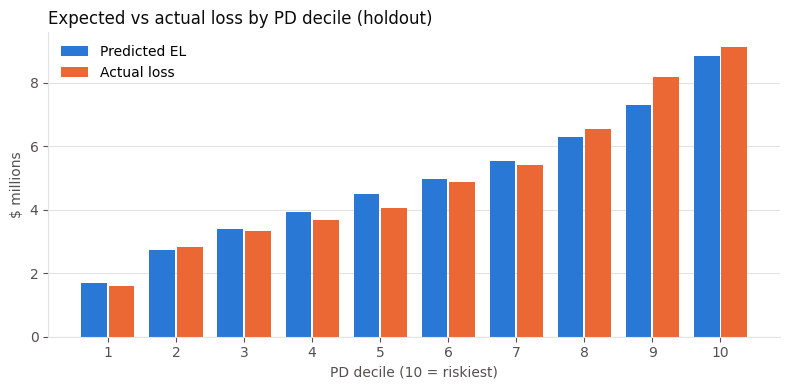

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
x = el_dec.index.to_numpy()
ax.bar(x - 0.2, el_dec["predicted_el"] / 1e6, 0.38, color=BLUE, label="Predicted EL")
ax.bar(x + 0.2, el_dec["actual_loss"] / 1e6, 0.38, color=ORANGE, label="Actual loss")
style(ax, "Expected vs actual loss by PD decile (holdout)", "PD decile (10 = riskiest)", "$ millions")
ax.set_xticks(x); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "el_vs_actual_by_decile.png", dpi=150); plt.show()

## Step 9. Credit VaR and Expected Shortfall (one-factor Vasicek)
Given the economy factor z: PD(z) = Φ((Φ⁻¹(PD) − √ρ·z) / √(1−ρ)); portfolio loss L(z) = Σ PD_i(z)·LGD_i·EAD_i.
1,000,000 simulated values of z; no per-loan simulation needed. Horizon: the 36-month life of the loans.

In [16]:
rows = []
for rho in RHO_GRID:
    r, _ = risk_report(h["pd"], h["lgd_hat"], h["ead_hat"], rho, f"rho = {rho:.0%}", QUANTILES)
    rows.append(r)
var_table = pd.DataFrame(rows).set_index("scenario") / 1e6
var_table.to_csv(RES / "var_es_by_rho.csv")
print("$ millions"); var_table.round(2)

$ millions


,EL,mean simulated loss,VaR 99.0%,ES 99.0%,VaR 99.9%,ES 99.9%
scenario,,,,,,
rho = 3%,49.1600,49.1500,85.7300,92.5400,101.3200,107.2400
rho = 8%,49.1600,49.1500,114.8700,128.1100,145.2000,156.5900
rho = 15%,49.1600,49.1500,147.2300,167.4600,193.4600,209.8500


rho = 8%: EL $49.2M | 99.9% VaR $145.2M | 99.9% ES $156.6M | economic capital (VaR - EL) $96.0M = 12.5% of funded


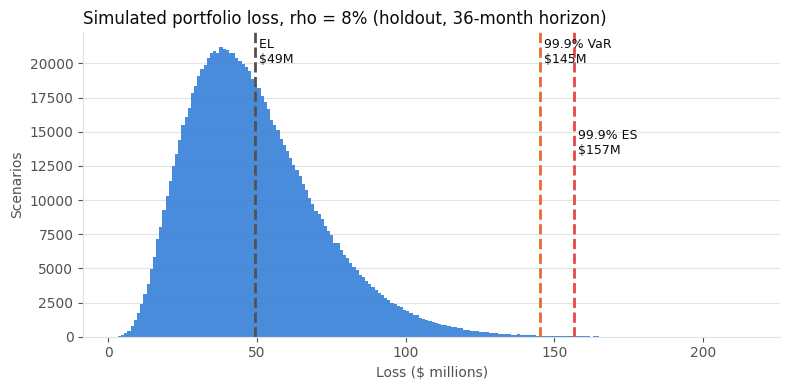

In [17]:
r_main, losses = risk_report(h["pd"], h["lgd_hat"], h["ead_hat"], RHO, "main", QUANTILES)
v999, es999 = var_es(losses, 0.999)
print(f"rho = {RHO:.0%}: EL ${r_main['EL']/1e6:.1f}M | 99.9% VaR ${v999/1e6:.1f}M | 99.9% ES ${es999/1e6:.1f}M | "
      f"economic capital (VaR - EL) ${(v999 - r_main['EL'])/1e6:.1f}M = {(v999 - r_main['EL'])/funded:.1%} of funded")
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(losses / 1e6, bins=200, color=BLUE, alpha=0.85)
for val, lab, c, y in [(r_main["EL"], "EL", INK2, 0.9), (v999, "99.9% VaR", ORANGE, 0.9), (es999, "99.9% ES", RED, 0.6)]:
    ax.axvline(val / 1e6, color=c, lw=2, ls="--"); ax.text(val / 1e6, ax.get_ylim()[1] * y, f" {lab}\n ${val/1e6:.0f}M", color=INK, fontsize=9)
style(ax, f"Simulated portfolio loss, rho = {RHO:.0%} (holdout, 36-month horizon)", "Loss ($ millions)", "Scenarios")
fig.tight_layout(); fig.savefig(FIG / "loss_distribution.png", dpi=150); plt.show()

In [18]:
# Basel IRB 'other retail': 1-year PD = lifetime PD x share of defaults in year 1 (Step 5)
pd_1y = np.clip(h["pd"].to_numpy() * F[12], PD_FLOOR, 0.999)
K = irb_capital_k(pd_1y, h["lgd_hat"].to_numpy())
irb_cap = (K * h["ead_hat"]).sum()
R_basel = irb_retail_correlation(pd_1y)
r1y, _ = risk_report(pd_1y, h["lgd_hat"], h["ead_hat"], R_basel, "1y, Basel R", (0.999,))
irb = pd.DataFrame({"value": {
    "average 1-year PD": pd_1y.mean(),
    "EAD-weighted Basel correlation R": np.average(R_basel, weights=h["ead_hat"]),
    "IRB capital K x EAD ($M)": irb_cap / 1e6,
    "RWA ($M)": irb_cap * 12.5 / 1e6,
    "RWA density (RWA / EAD)": irb_cap * 12.5 / h["ead_hat"].sum(),
    "Simulation check: 1y 99.9% VaR - EL ($M)": (r1y["VaR 99.9%"] - r1y["EL"]) / 1e6}})
irb.to_csv(RES / "irb_comparison.csv")
irb

,value
average 1-year PD,0.0301
EAD-weighted Basel correlation R,0.0815
IRB capital K x EAD ($M),40.4278
RWA ($M),505.3471
RWA density (RWA / EAD),1.1862
Simulation check: 1y 99.9% VaR - EL ($M),40.8330


## Step 10. Stress testing

In [19]:
rows = []
for name, (pd_mult, lgd_add) in STRESS.items():
    r, _ = risk_report(np.clip(h["pd"] * pd_mult, 0, 0.999), np.clip(h["lgd_hat"] + lgd_add, 0, 1),
                       h["ead_hat"], RHO, name, QUANTILES)
    rows.append(r)
stress = pd.DataFrame(rows).set_index("scenario") / 1e6
stress["EL % funded"] = stress["EL"] * 1e6 / funded * 100
stress.to_csv(RES / "stress_tests.csv")
print(f"$ millions, rho = {RHO:.0%}"); stress[["EL", "VaR 99.9%", "ES 99.9%", "EL % funded"]].round(2)

$ millions, rho = 8%


,EL,VaR 99.9%,ES 99.9%,EL % funded
scenario,,,,
Base,49.1600,145.2000,156.5900,6.4200
PD x1.5,73.7400,184.5400,196.0400,9.6400
PD x2,98.3300,216.1100,227.0900,12.8500
LGD +10 pts,54.7000,161.5400,174.2100,7.1500
"PD x2, LGD +10 pts",109.3900,240.4200,252.6300,14.2900


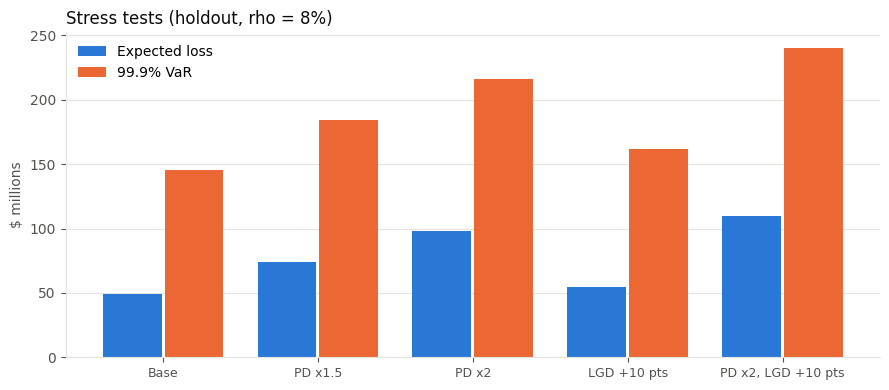

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(stress))
ax.bar(x - 0.2, stress["EL"], 0.38, color=BLUE, label="Expected loss")
ax.bar(x + 0.2, stress["VaR 99.9%"], 0.38, color=ORANGE, label="99.9% VaR")
style(ax, f"Stress tests (holdout, rho = {RHO:.0%})", "", "$ millions")
ax.set_xticks(x); ax.set_xticklabels(stress.index, fontsize=9); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "stress_tests.png", dpi=150); plt.show()

## Step 11. PD model validation

In [21]:
val = pd.DataFrame({"dev": validation_summary(dev["default"], dev["pd"]),
                    "test": validation_summary(test["default"], test["pd"]),
                    "holdout": validation_summary(h["default"], h["pd"])})
val

,dev,test,holdout
AUC,0.6536,0.6543,0.6501
Gini,0.3071,0.3087,0.3003
KS,0.2195,0.2312,0.2224


In [22]:
cal = h.groupby("decile").agg(loans=("id", "size"), predicted=("pd", "mean"), actual=("default", "mean"))
cal["z"] = (cal["actual"] - cal["predicted"]) / np.sqrt(cal["predicted"] * (1 - cal["predicted"]) / cal["loans"])
cal.to_csv(RES / "pd_calibration_holdout.csv")
cal   # |z| > 2 = gap larger than chance would explain

,loans,predicted,actual,z
decile,,,,
1,6096,0.0425,0.0441,0.6279
2,6096,0.0691,0.0714,0.6883
3,6096,0.0865,0.0883,0.4766
4,6095,0.1015,0.1001,-0.3588
5,6096,0.1161,0.1076,-2.0769
6,6096,0.1315,0.1370,1.2564
7,6095,0.1486,0.1462,-0.5203
8,6096,0.1687,0.1734,0.9838
9,6096,0.1970,0.2106,2.6824


In [23]:
psi_split, psi_tab = psi(dev["pd"].to_numpy(), h["pd"].to_numpy())
psi_vint, _ = psi(dev.loc[dev["issue_d"].dt.year == 2012, "pd"].to_numpy(),
                  h.loc[h["issue_d"].dt.year == 2014, "pd"].to_numpy())
print(f"PSI dev vs holdout: {psi_split:.4f}")
print(f"PSI 2012 loans (dev) vs 2014 loans (holdout): {psi_vint:.4f}")
print("Rule of thumb: < 0.10 stable, 0.10-0.25 watch, > 0.25 investigate")
val.loc["PSI vs dev"] = [np.nan, np.nan, round(psi_split, 4)]
val.loc["PSI 2012 vs 2014"] = [np.nan, np.nan, round(psi_vint, 4)]
val.to_csv(RES / "pd_validation.csv"); psi_tab.to_csv(RES / "psi_table.csv", index=False)

PSI dev vs holdout: 0.0001
PSI 2012 loans (dev) vs 2014 loans (holdout): 0.0151
Rule of thumb: < 0.10 stable, 0.10-0.25 watch, > 0.25 investigate


## Step 12. Concentration risk (holdout book)

In [24]:
conc = []
for col in ["addr_state", "purpose", "grade"]:
    share = h.groupby(col)["funded_amnt"].sum() / funded
    top = share.sort_values(ascending=False).head(3)
    conc.append({"dimension": col, "groups": len(share), "HHI": (share ** 2).sum(),
                 "effective number": 1 / (share ** 2).sum(),
                 "top 3": ", ".join(f"{k} {v:.1%}" for k, v in top.items())})
conc = pd.DataFrame(conc)
conc.to_csv(RES / "concentration.csv", index=False)
conc

,dimension,groups,HHI,effective number,top 3
0,addr_state,47,0.0591,16.9109,"CA 16.2%, NY 8.7%, TX 8.7%"
1,purpose,12,0.4347,2.3006,"debt_consolidation 60.2%, credit_card 26.2%, h..."
2,grade,7,0.2604,3.8409,"B 36.1%, C 24.5%, A 23.2%"


## Step 13. IFRS 9 staging and ECL, 12 months after issue
- **Off book:** repaid before month 12.
- **Stage 3:** 90+ days past due (3+ payments missed at month 12).
- **Stage 2:** 30+ days past due (2 payments missed), or the Step 7 rule (PD ≥ cut).
- **Stage 1:** everything else.

ECL = Σ over future months of marginal PD × LGD × scheduled balance (no discounting).
Stage 1: next 12 months · Stage 2: remaining life · Stage 3: LGD × balance at default.

In [25]:
REPORT_MONTH = 12
missed = REPORT_MONTH - months_between(h["issue_d"], h["last_pymnt_d"]).fillna(0)
off_book = (h["default"] == 0) & (missed > 0)
stage3 = (h["default"] == 1) & (missed >= 3)
stage2 = ((h["default"] == 1) & (missed == 2)) | (h["pd"] >= sicr_cut)
h["stage"] = np.select([off_book, stage3, stage2], ["off book", "Stage 3", "Stage 2"], "Stage 1")
h["stage"].value_counts()

stage
Stage 1     49381
off book     7627
Stage 2      2068
Stage 3      1882
Name: count, dtype: int64

In [26]:
months = np.arange(REPORT_MONTH + 1, 37)
dF = F.loc[months].to_numpy() - F.loc[months - 1].to_numpy()          # share of lifetime defaults per month
alive = 1 - h["pd"].to_numpy() * F[REPORT_MONTH]                       # not yet defaulted at month 12
marg_pd = h["pd"].to_numpy()[:, None] * dF[None, :] / alive[:, None]   # loans x months
bal = scheduled_balance(h["funded_amnt"].to_numpy()[:, None], h["int_rate"].to_numpy()[:, None], months[None, :] - 1)
loss_m = marg_pd * bal * h["lgd_hat"].to_numpy()[:, None]
h["ecl_12m"] = loss_m[:, months <= REPORT_MONTH + 12].sum(axis=1)
h["ecl_life"] = loss_m.sum(axis=1)
h["ecl"] = np.select([h["stage"] == "Stage 1", h["stage"] == "Stage 2", h["stage"] == "Stage 3"],
                     [h["ecl_12m"], h["ecl_life"], h["lgd_hat"] * h["ead"]], 0.0)
h["balance_12"] = np.select([h["stage"] == "Stage 3", h["stage"] == "off book"],
                            [h["ead"], 0.0], scheduled_balance(h["funded_amnt"], h["int_rate"], REPORT_MONTH))

In [27]:
on = h[h["stage"] != "off book"]
ifrs = on.groupby("stage").agg(loans=("id", "size"), balance=("balance_12", "sum"), ecl=("ecl", "sum"),
                               later_default_rate=("default", "mean"))
ifrs["coverage"] = ifrs["ecl"] / ifrs["balance"]
ifrs.loc["Total"] = [ifrs["loans"].sum(), ifrs["balance"].sum(), ifrs["ecl"].sum(),
                     on["default"].mean(), ifrs["ecl"].sum() / ifrs["balance"].sum()]
ifrs.to_csv(RES / "ifrs9_staging_month12.csv")
perf = on[on["stage"] != "Stage 3"]
print(f"Performing loans: ECL ${perf['ecl_12m'].sum()/1e6:.1f}M if all Stage 1, "
      f"${perf['ecl_life'].sum()/1e6:.1f}M if all lifetime, ${perf['ecl'].sum()/1e6:.1f}M with staging")
ifrs

Performing loans: ECL $19.1M if all Stage 1, $24.6M if all lifetime, $19.5M with staging


,loans,balance,ecl,later_default_rate,coverage
stage,,,,,
Stage 1,"49,381.0000","447,118,432.9445","17,649,706.6496",0.1117,0.0395
Stage 2,"2,068.0000","15,057,737.7489","1,836,887.3092",0.3337,0.1220
Stage 3,"1,882.0000","18,968,880.7100","16,825,797.7862",1.0000,0.8870
Total,"53,331.0000","481,145,051.4034","36,312,391.7450",0.1517,0.0755


Result tables are in `results/`, charts in `figures/`, and the write-up in `EXPLAINER.md`.